In [186]:
import numpy as np
import sklearn 
from matplotlib import pyplot as plt
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [187]:
titanic=sklearn.datasets.fetch_openml('titanic', version=1)
print('len:',len(titanic['data']))
titanic.frame.info()

len: 1309
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   str     
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   str     
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    str     
 10  embarked   1307 non-null   category
 11  boat       486 non-null    str     
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    str     
dtypes: category(3), float64(3), int64(3), str(5)
memory usage: 116.5 KB


In [188]:
for i in titanic.frame.columns.tolist():
    print(i,titanic.frame[i].nunique())
# попробовать добавить tiket
data=titanic['data']
data=data.drop(['body','boat','name','ticket','home.dest'],axis=1)
data['age']=data['age'].fillna(0,inplace=True)
data['fare']=data['fare'].fillna(0,inplace=True)
data['cabin']=data['cabin'].fillna('U',inplace=True)
data['embarked']=data['embarked'].fillna('S')
data['cabin']=data['cabin'].str[0]



for i in data:
    print(i,end='|')
data

pclass 3
survived 2
name 1307
sex 2
age 98
sibsp 7
parch 8
ticket 929
fare 281
cabin 186
embarked 3
boat 27
body 121
home.dest 369
pclass|sex|age|sibsp|parch|fare|cabin|embarked|

C:\Users\user\AppData\Local\Temp\ipykernel_17296\2149467774.py:6: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  data['age']=data['age'].fillna(0,inplace=True)
C:\Users\user\AppData\Local\Temp\ipykernel_17296\2149467774.py:7: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment usi

,pclass,sex,age,sibsp,parch,fare,cabin,embarked
0,1,female,29.0000,0,0,211.3375,B,S
1,1,male,0.9167,1,2,151.5500,C,S
2,1,female,2.0000,1,2,151.5500,C,S
3,1,male,30.0000,1,2,151.5500,C,S
4,1,female,25.0000,1,2,151.5500,C,S
...,...,...,...,...,...,...,...,...
1304,3,female,14.5000,1,0,14.4542,U,C
1305,3,female,0.0000,1,0,14.4542,U,C
1306,3,male,26.5000,0,0,7.2250,U,C
1307,3,male,27.0000,0,0,7.2250,U,C


Необходимо нармолизовать данные

In [189]:
data=pd.get_dummies(data,columns=['pclass','sex','cabin','embarked'],dtype=int)


data_train=data.sample(frac=0.7,random_state=1)
data_val=data.drop(data_train.index).sample(frac=1.0,random_state=2)


y_train=titanic['target'].sample(frac=0.7,random_state=1)
y_val=titanic['target'].drop(y_train.index).sample(frac=1.0,random_state=2)



max_age=data_train['age'].max()
max_sibsp=data_train['sibsp'].max()
max_parch=data_train['parch'].max()
max_fare=data_train['fare'].max()

data_train['age'] /=max_age
data_train['sibsp']/=max_sibsp
data_train['parch']/=max_parch
data_train['fare']/=max_fare

data_val['age']/=max_age
data_val['sibsp']/=max_sibsp
data_val['parch']/= max_parch
data_val['fare']/=max_fare

# удаление выбросов
data_val=data_val[(data_val['cabin_G']==0) & (data_val['cabin_T']==0)]
data_train=data_train[(data_train['cabin_G']==0) & (data_train['cabin_T']==0)]
data_train=data_train.drop(['cabin_G','cabin_T'],axis=1)
data_val=data_val.drop(['cabin_G','cabin_T'],axis=1)

print('shape data-val:',data_val.shape)
print('shape data-train:',data_train.shape)


shape data-val: (391, 19)
shape data-train: (912, 19)


Посмторим что получилось

In [190]:
data_train.to_excel('2.xlsx')
data_train

,age,sibsp,parch,fare,pclass_1,pclass_2,pclass_3,sex_female,sex_male,cabin_A,cabin_B,cabin_C,cabin_D,cabin_E,cabin_F,cabin_U,embarked_C,embarked_Q,embarked_S
201,0.6750,0.000,0.000000,0.101229,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1
115,0.8000,0.125,0.444444,0.513342,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1
255,0.3000,0.000,0.000000,0.135265,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0
1103,0.0250,0.500,0.111111,0.077465,0,0,1,0,1,0,0,0,0,0,0,1,0,0,1
195,0.2000,0.000,0.000000,0.168837,1,0,0,1,0,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
396,0.4250,0.000,0.111111,0.044893,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1
787,0.2000,0.000,0.000000,0.015176,0,0,1,0,1,0,0,0,0,0,0,1,0,0,1
501,0.1625,0.000,0.111111,0.038061,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1
816,0.0000,0.000,0.000000,0.015412,0,0,1,0,1,0,0,0,0,0,0,1,1,0,0


Проверим на кореляцию

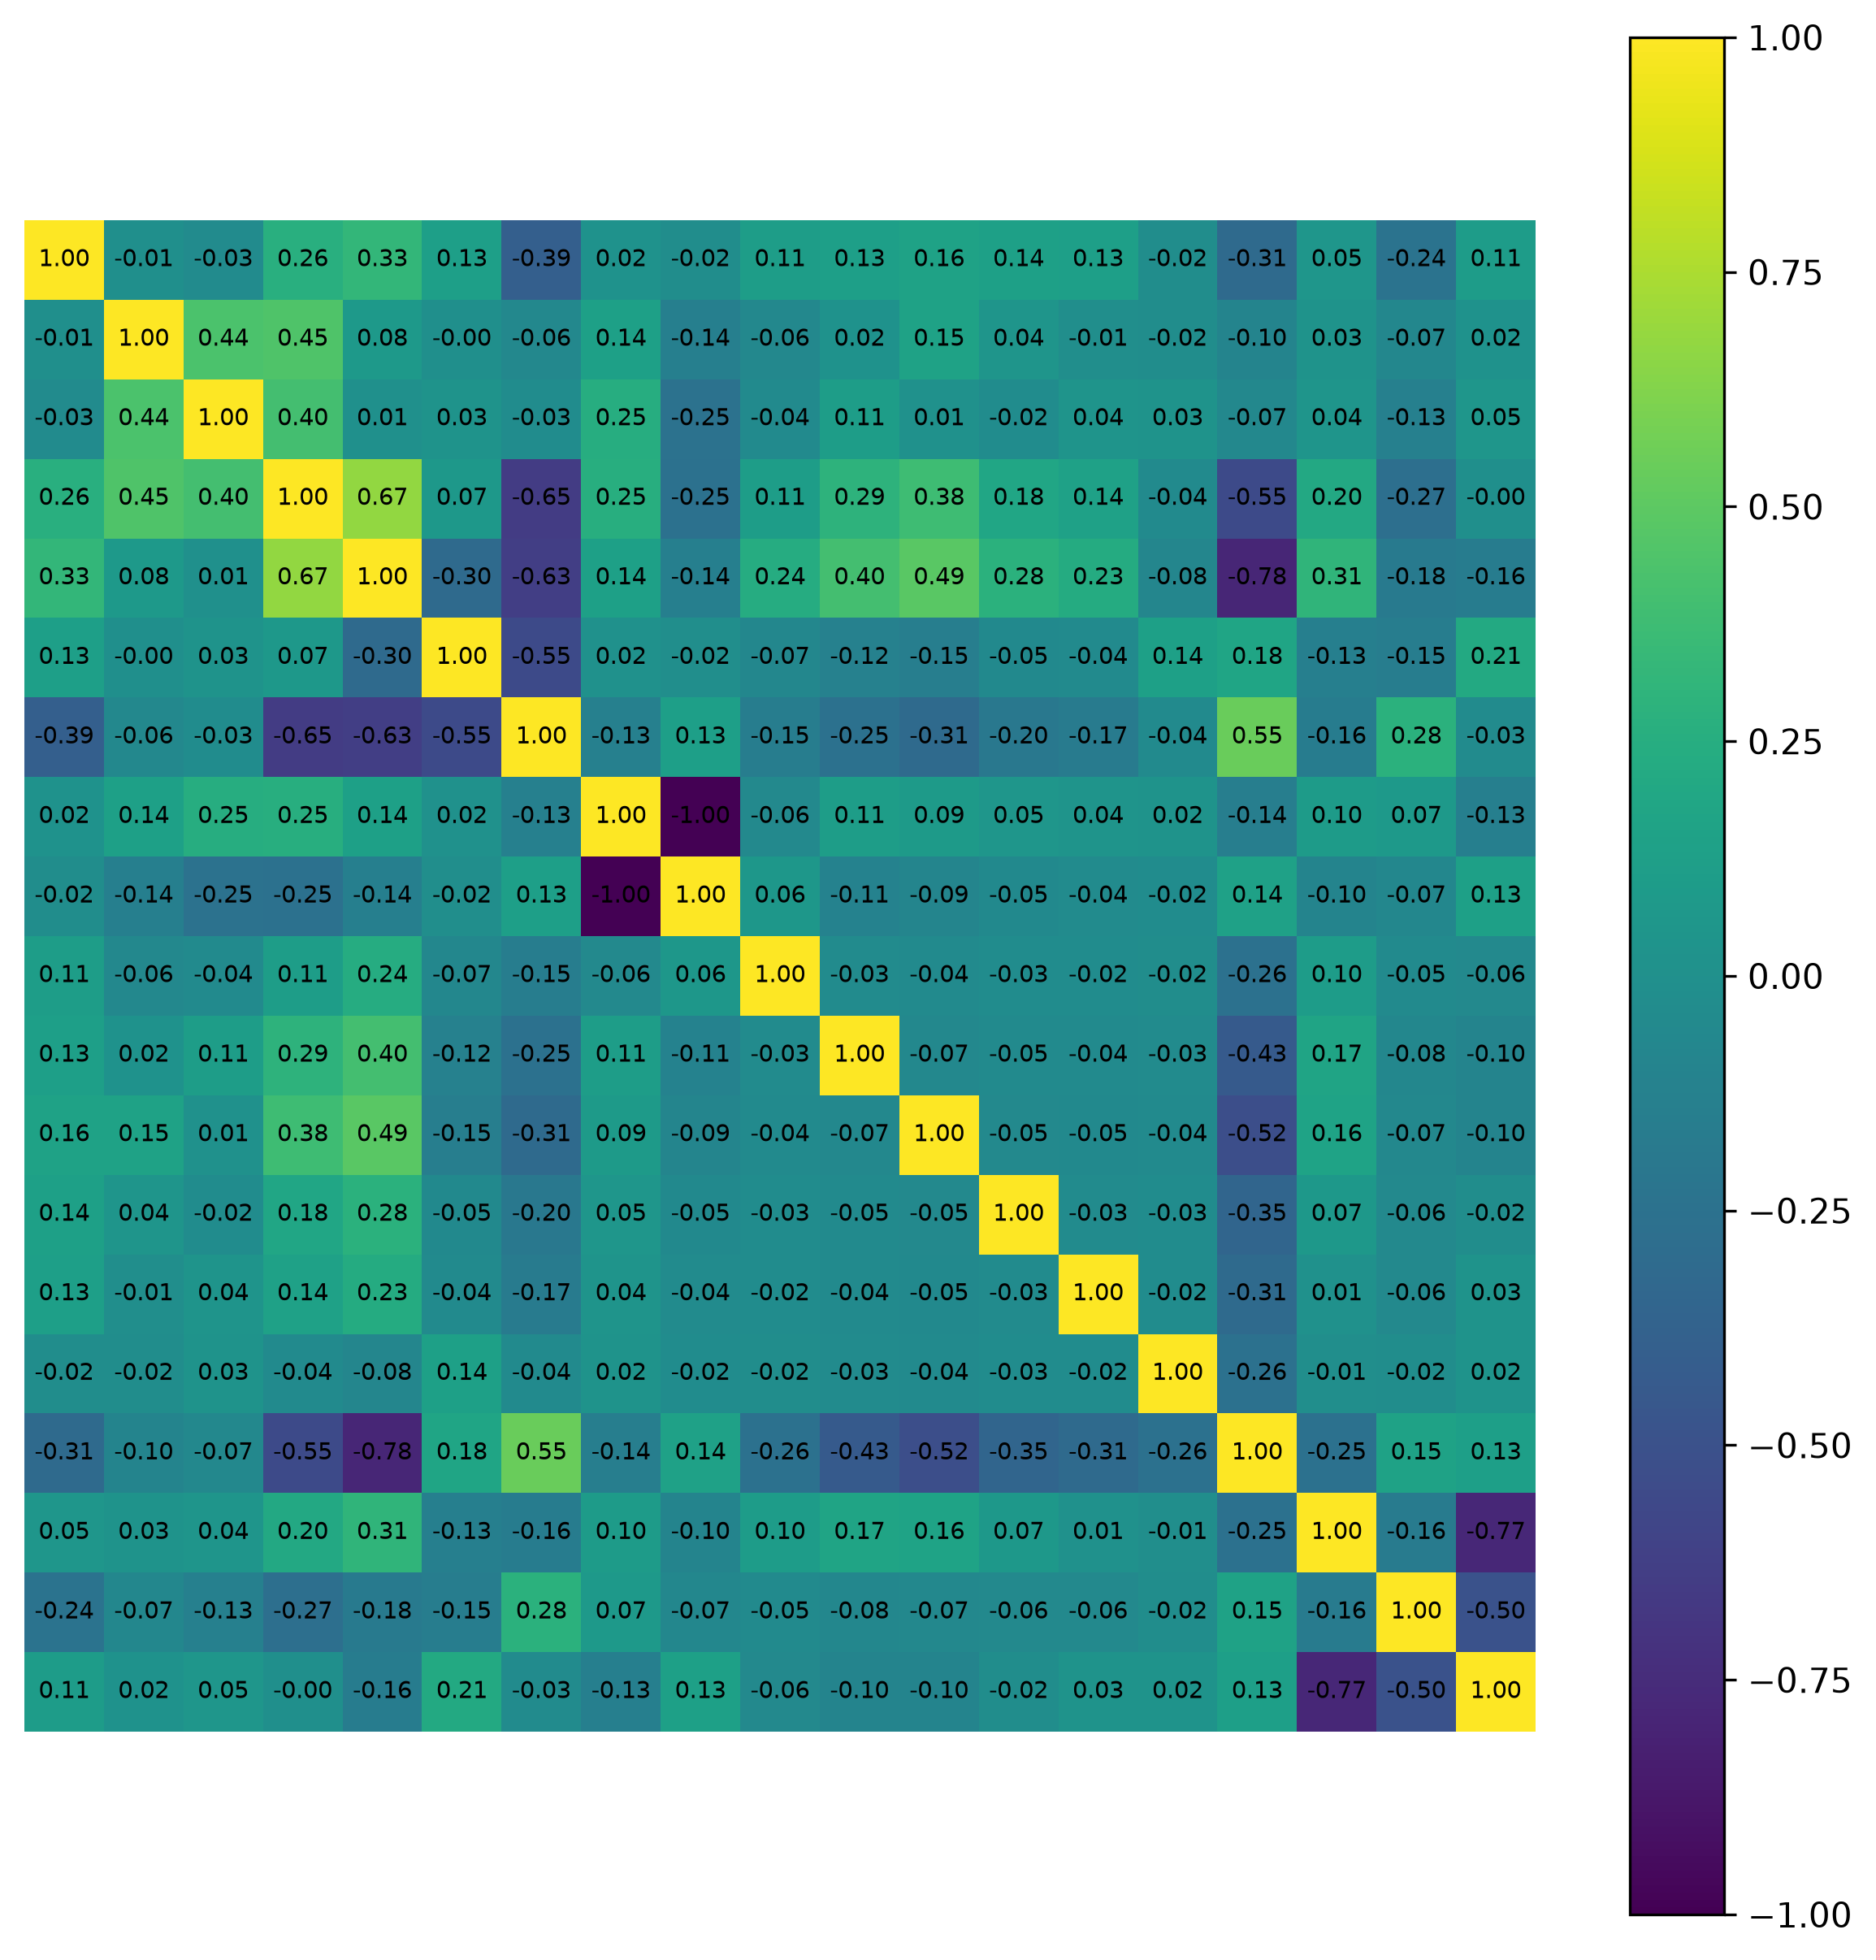

In [191]:
cor=data_train.corr(method='spearman')
plt.figure(figsize=(10,10),dpi=300)
fig=plt.imshow(cor)
plt.colorbar(fig)
for x,x_v in enumerate(cor.columns):
    for y,y_v in enumerate(cor.columns):
        t=f'{cor[x_v][y_v]:.2f}'
        plt.text(x,y,t,ha='center',va='center',fontsize=7)
plt.axis('off')
plt.show()

Судя по этой таблице кореляции спирменя можно сказать что прям серьезных кореляцый монотоных мы не наблюдаем, кроме тех которые являются One-Hot кодированием. И соотвественно это не сильно должно мешать.

Поиск выбросов:

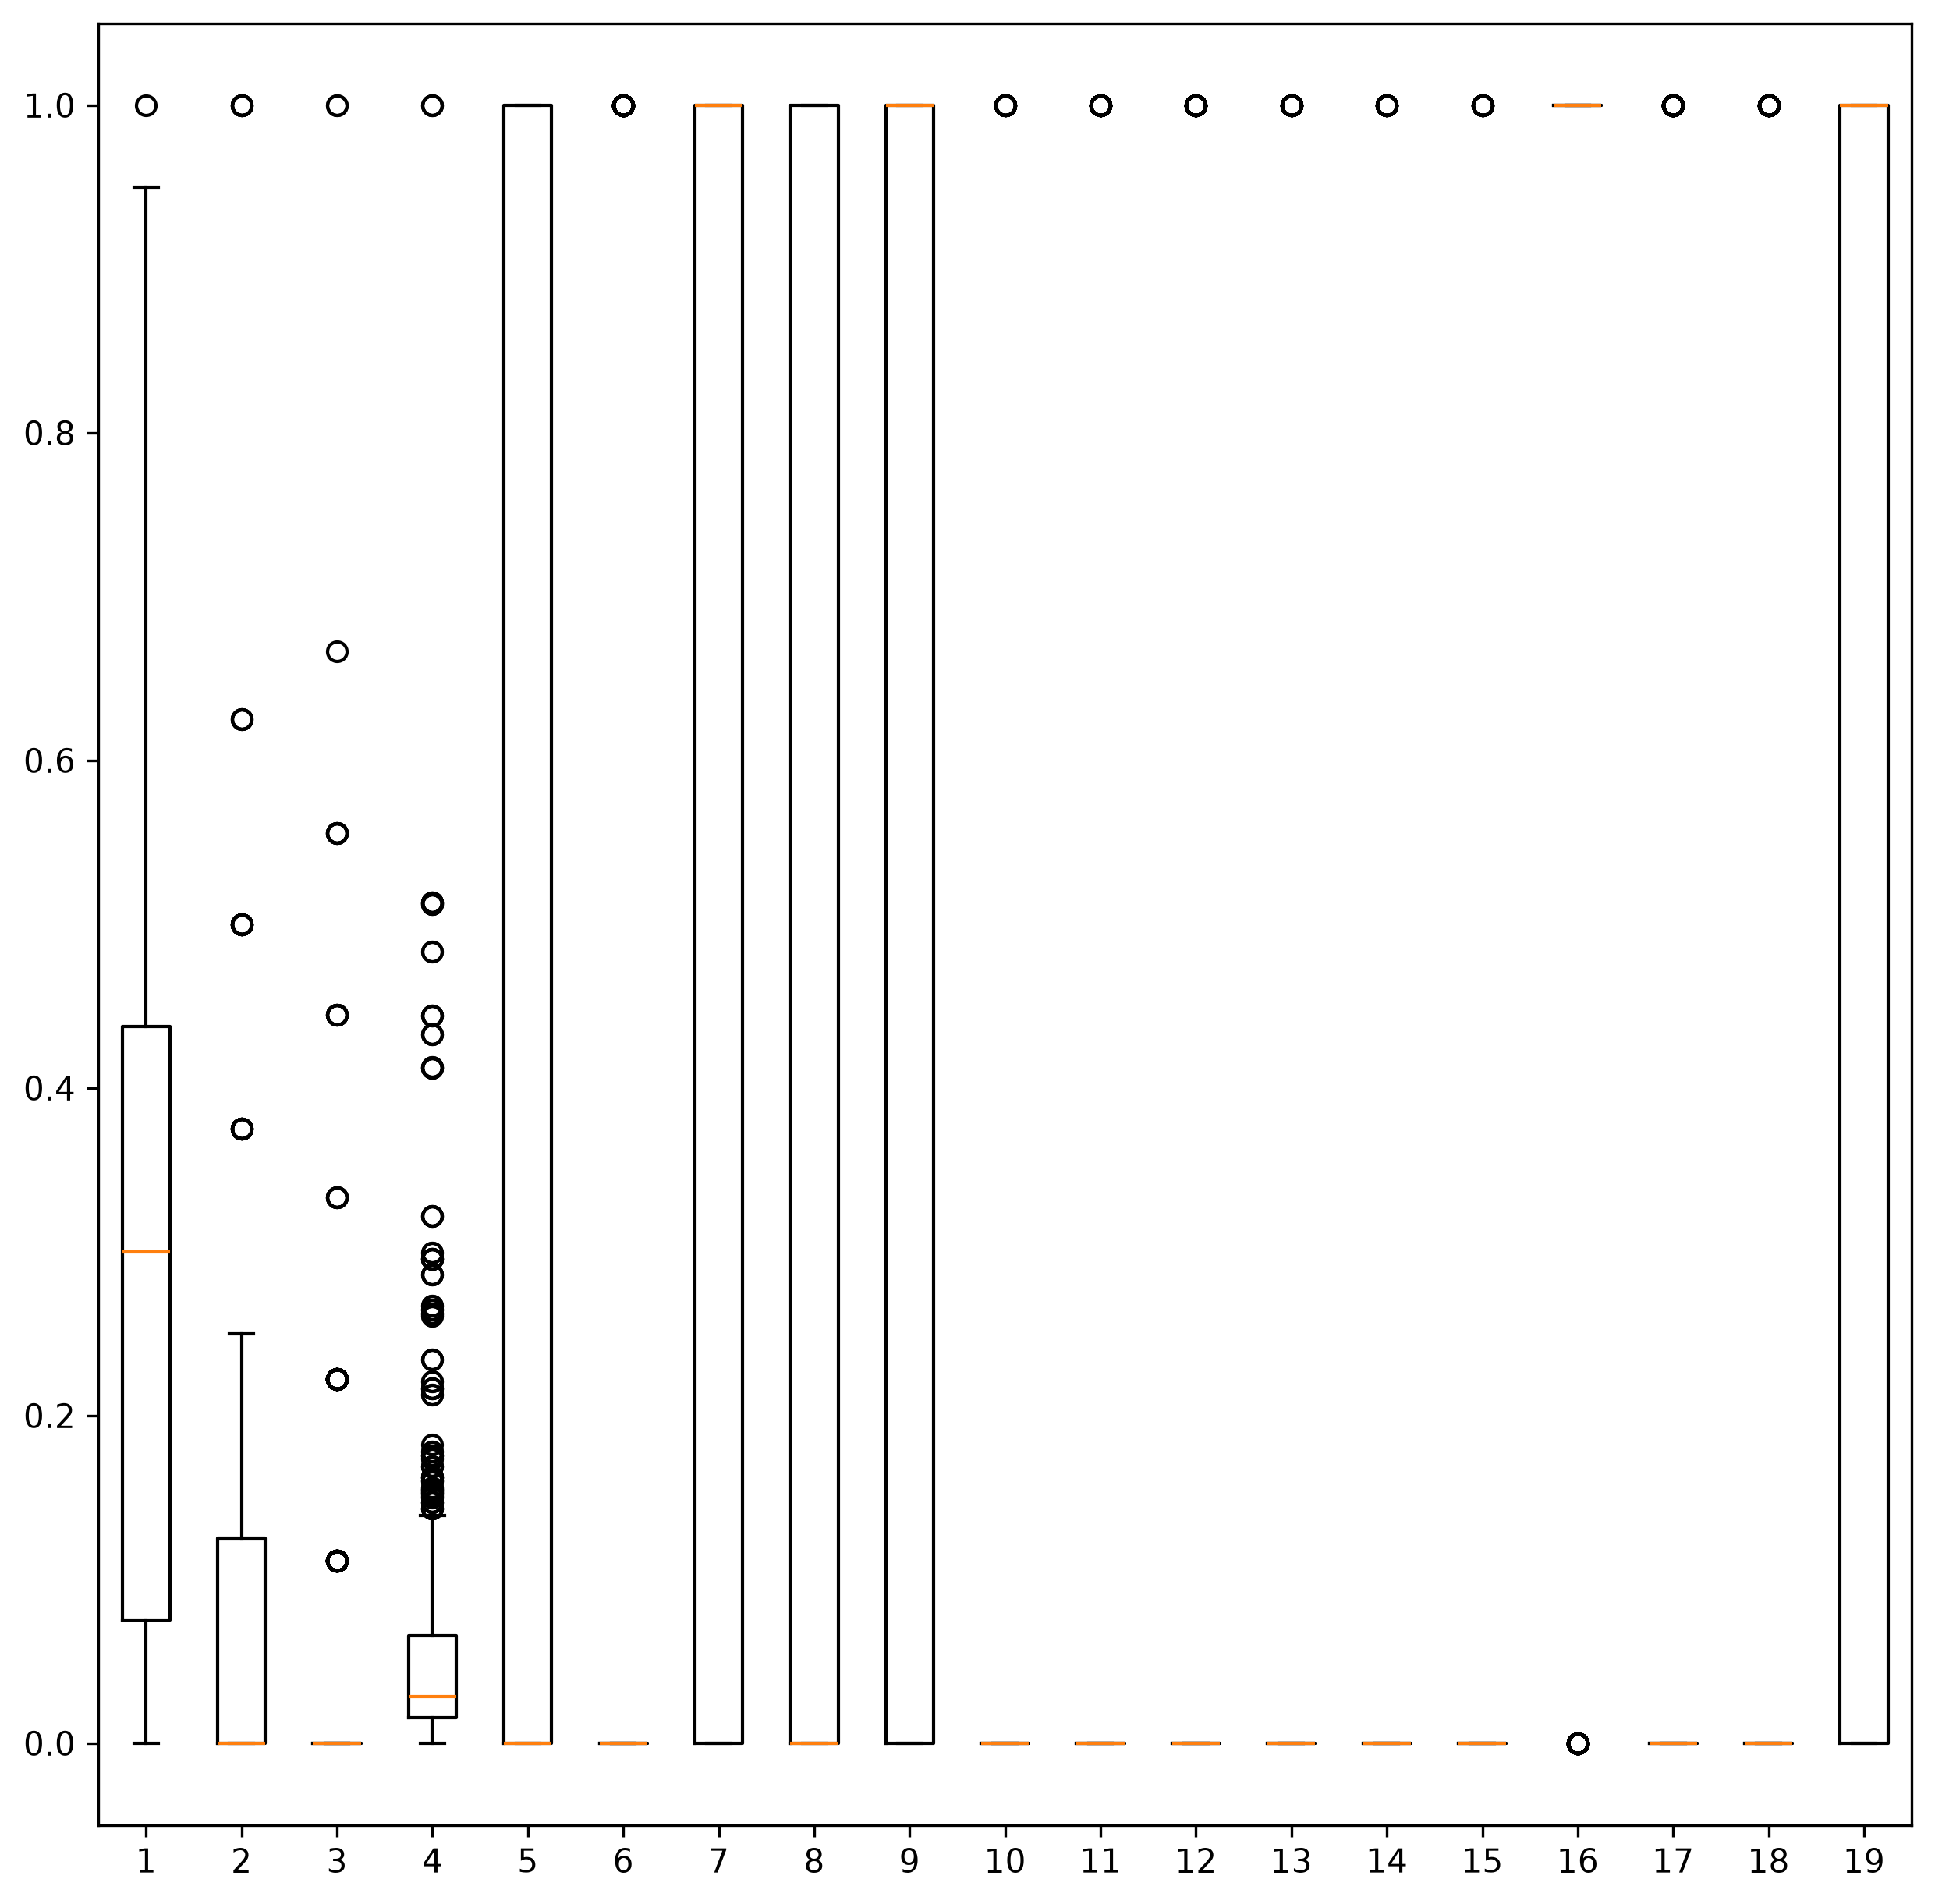

In [192]:
with open('value_couts,txt','w') as f:

    for i in data_train.columns:
        f.write(f'{i}: {data_train[i].value_counts()} \n')

fig=plt.figure(figsize=(10,10),dpi=300)
plt.boxplot(data_train)
plt.show()

Судя по данной картинке можно сказать что есть большие выбросы в 4 колонке с ценой билета, но по идее логистическая регреси к выбросам устойчива. Надо проверить по метрикам.

In [193]:
vif=pd.DataFrame()
vif['feature']=data_val.columns
print(data_val.shape[1])
vif['VIF']=[variance_inflation_factor(data_val.values,i) for i in range(data_val.shape[1])]
vif

19


C:\Users\user\AppData\Local\Temp\ipykernel_17296\2372917626.py:4: UserWarning: The design matrix is poorly conditioned (condition number=1.17e+17). VIF calculations may be numerically unstable.
  vif['VIF']=[variance_inflation_factor(data_val.values,i) for i in range(data_val.shape[1])]
d:\Python\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\Python\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\Python\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\Python\Lib\site-packages\statsmodels\

,feature,VIF
0,age,1.312093e+00
1,sibsp,1.304837e+00
2,parch,1.392637e+00
3,fare,2.107947e+00
4,pclass_1,1.000800e+15
5,pclass_2,1.000800e+15
6,pclass_3,1.000800e+15
7,sex_female,1.000800e+15
8,sex_male,1.000800e+15
9,cabin_A,1.000800e+15


Исходя из этого мы видим что мультиколениарность присутвует у значений с one-hot кодированием и неоходимо это убрать. Для этого стоит убрать по 1 столбцу.  

In [194]:
with open('value_counts.txt','w') as f:
    for i in data_train.columns[4:]:
        f.write(f'------------\n{i} {data_train[i].value_counts()}')

In [195]:
data_train=data_train.drop(['embarked_C','cabin_U','sex_male','pclass_1'],axis=1)
data_val=data_val.drop(['embarked_C','cabin_U','sex_male','pclass_1'],axis=1)
print('len columns:',len(data_train.columns))

len columns: 15


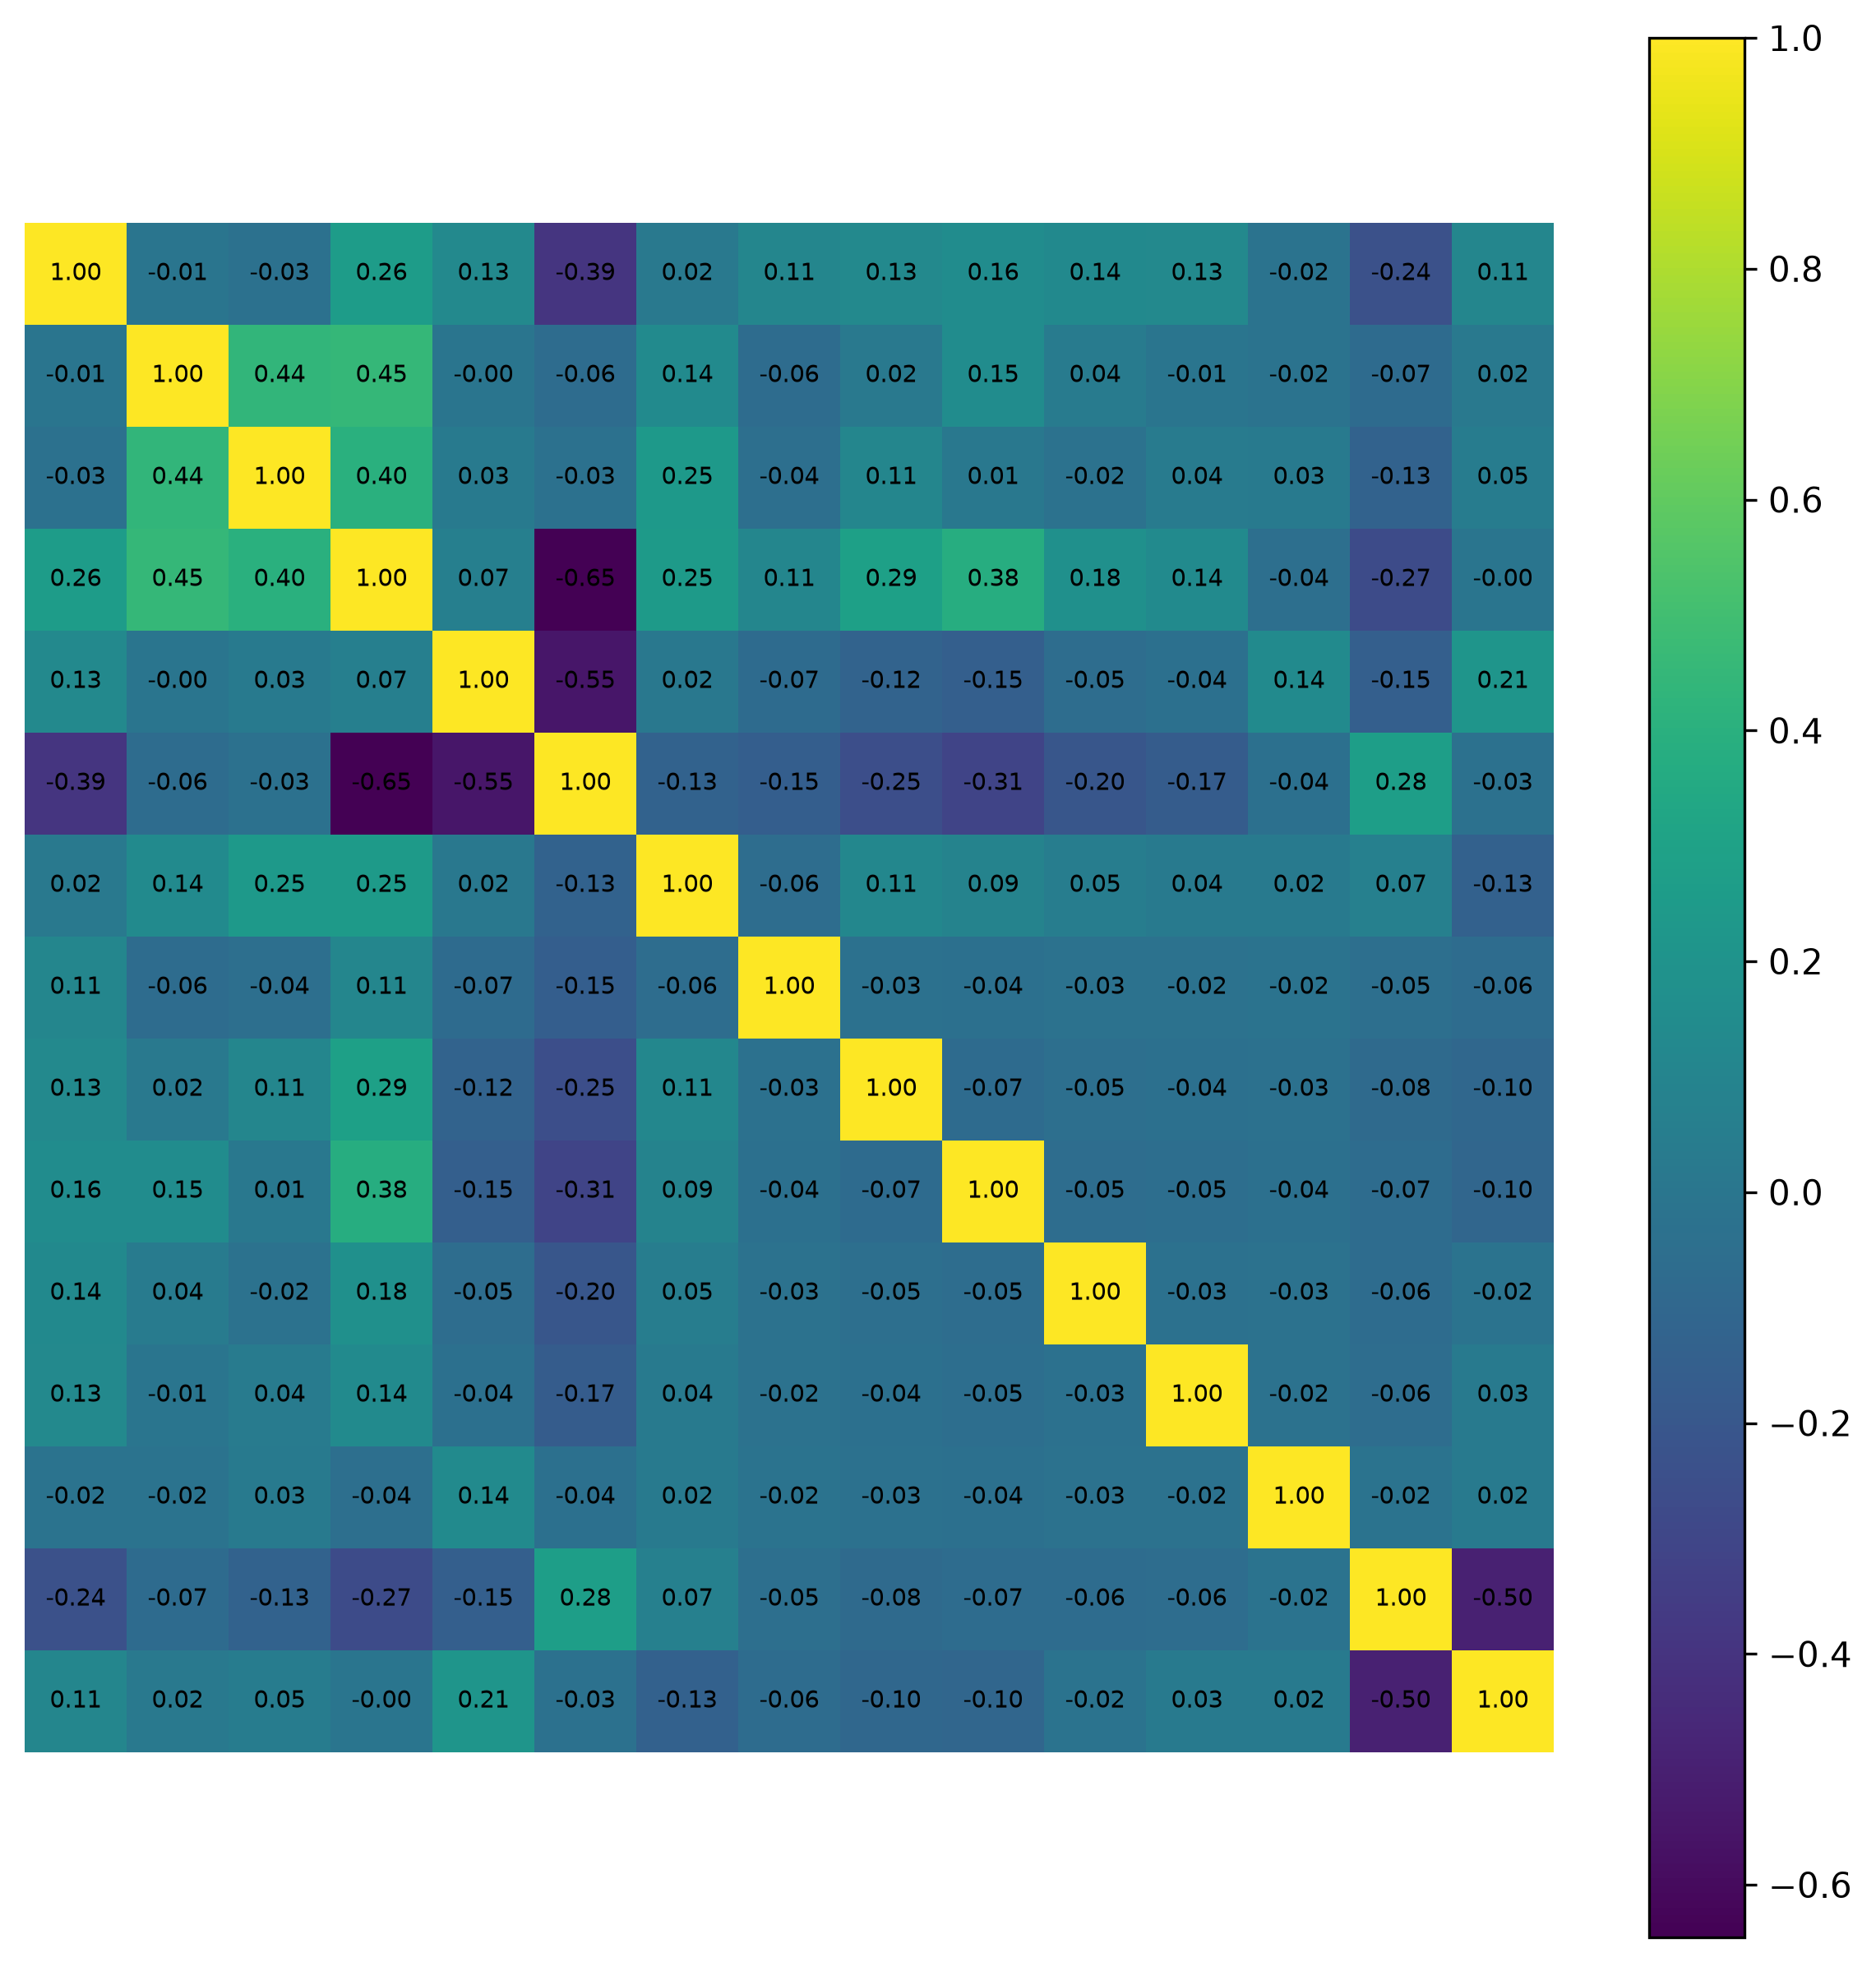

In [196]:
cor=data_train.corr(method='spearman')
plt.figure(figsize=(10,10),dpi=300)
fig=plt.imshow(cor)
plt.colorbar(fig)
for x,x_v in enumerate(cor.columns):
    for y,y_v in enumerate(cor.columns):
        t=f'{cor[x_v][y_v]:.2f}'
        plt.text(x,y,t,ha='center',va='center',fontsize=7)
plt.axis('off')
plt.show()


In [197]:
vif=pd.DataFrame()
vif['feature']=data_train.columns
print(data_train.shape[1])
vif['VIF']=[variance_inflation_factor(data_train.values,i) for i in range(data_train.shape[1])]
vif

15


,feature,VIF
0,age,1.283965
1,sibsp,1.218239
2,parch,1.266079
3,fare,1.983332
4,pclass_2,3.855221
5,pclass_3,5.615577
6,sex_female,1.119939
7,cabin_A,1.335789
8,cabin_B,1.858414
9,cabin_C,2.166158


In [198]:
data_train=data_train.to_numpy()
data_val=data_val.to_numpy()
y_train=y_train.to_numpy()
y_val=y_val.to_numpy()
np.savez_compressed('dataset.npz',
                    data_train=data_train,data_val=data_val,
                    y_train=y_train,y_val=y_val)
